In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
## Data preparation
df = pd.read_csv('course_lead_scoring_2026.csv')

In [3]:
df.head()
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [4]:
# check for missing values
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [5]:
categorical = []
numerical = []
for col in df.columns:
    if df[col].dtype == 'str':
        categorical.append(col)
    elif df[col].dtype == 'float64' or df[col].dtype == 'int64':
        numerical.append(col)

In [6]:
print("Categorical columns:", categorical)
print("# of categorical columns:", len(categorical))
print("Numerical columns:", numerical)
print("# of numerical columns:", len(numerical))


Categorical columns: ['lead_source', 'industry', 'employment_status', 'location']
# of categorical columns: 4
Numerical columns: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score', 'converted']
# of numerical columns: 5


In [7]:
# fill missing values for categorical columns with 'NA'
for col in categorical:
    df[col] = df[col].fillna('NA')
# fill missing values for numerical columns with 0.0
for col in numerical:
    df[col] = df[col].fillna(0.0)

In [8]:
# check for missing values
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [9]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NA,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [10]:
## split the data into 3 parts 
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [16]:
print(df_train.head())
print(y_train[1:5])

      lead_source    industry employment_status location  annual_income  \
0        paid_ads  technology          employed     asia        80198.0   
1        paid_ads      retail          employed     asia        50548.0   
2              NA     finance          employed       NA        76300.0   
3        paid_ads     finance          employed       NA        80371.0   
4  organic_search     finance          employed     asia        73567.0   

   number_of_courses_viewed  interaction_count  lead_score  
0                         5                  9        0.91  
1                         2                  5        0.48  
2                         0                  3        0.42  
3                         2                  6        0.49  
4                         2                  4        0.48  
[0 0 0 1]


In [17]:
## Question 1: ROC AUC feature importance
## 
from sklearn.metrics import roc_auc_score

features = [
    'lead_score',
    'number_of_courses_viewed',
    'interaction_count',
    'annual_income'
]
print("Feature Importance (ROC AUC):")
for feature in features:
    auc = roc_auc_score(y_train, df_train[feature])

    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[feature])

    print(feature, auc)

Feature Importance (ROC AUC):
lead_score 0.7882254810906102
number_of_courses_viewed 0.7229894623989618
interaction_count 0.7649203047563227
annual_income 0.6081977776250831


In [ ]:
## Question 2: Training the model
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# 2. convert the data into dictionaries
train_dict = df_train.to_dict(orient='records')
val_dict = df_val.to_dict(orient='records')

# 3. One-hot encoding
dv = DictVectorizer(sparse=False)

X_train_encoded = dv.fit_transform(train_dict)
X_val_encoded = dv.transform(val_dict)

# 4. Logistic Regression 학습
model = LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000
)

model.fit(X_train_encoded, y_train)

# 5. Validation 데이터 예측 확률
y_pred = model.predict_proba(X_val_encoded)[:, 1]

# 6. ROC AUC
auc = roc_auc_score(y_val, y_pred)

print(round(auc, 3))

0.732


Threshold: 0.63
Precision: 0.7327586206896551
Recall: 0.7252559726962458


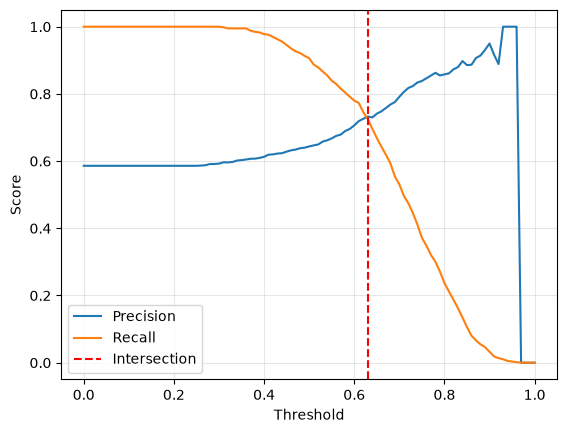

In [ ]:
## Question 3: Precision and Recall

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score

thresholds = np.arange(0, 1.01, 0.01)

precisions = []
recalls = []

for t in thresholds:
    y_pred_binary = (y_pred >= t).astype(int)

    p = precision_score(y_val, y_pred_binary, zero_division=0)
    r = recall_score(y_val, y_pred_binary, zero_division=0)

    precisions.append(p)
    recalls.append(r)

# calcuate the absolute difference between precision and recall
precisions = np.array(precisions)
recalls = np.array(recalls)

diff = np.abs(precisions - recalls)

# exclude thresholds where both precision and recall are zero to avoid division by zero
valid = ~((precisions == 0) & (recalls == 0))
diff[~valid] = np.inf

# The smallest difference threshold
idx = np.argmin(diff)

print("Threshold:", round(thresholds[idx], 2))
print("Precision:", precisions[idx])
print("Recall:", recalls[idx])

# Plot
plt.plot(thresholds, precisions, label="Precision")
plt.plot(thresholds, recalls, label="Recall")

plt.axvline(thresholds[idx], color="red",
            linestyle="--", label="Intersection")

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Best threshold: 0.41000000000000003
Maximum F1: 0.7576158940397352


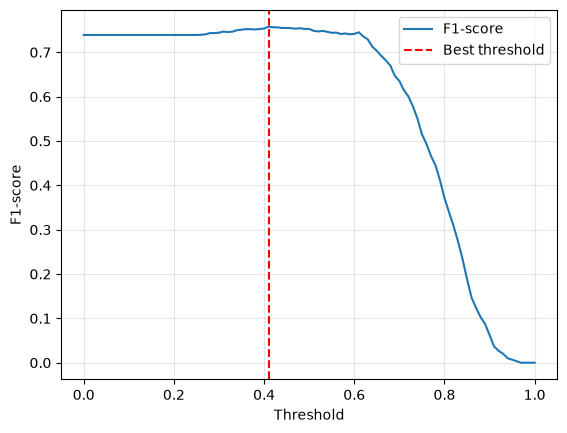

In [23]:
## Question 4: F1-score
f1_scores = np.divide(
    2 * precisions * recalls,
    precisions + recalls,
    out=np.zeros_like(precisions),
    where=(precisions + recalls) != 0
)

# 최대 F1-score의 threshold
best_idx = np.argmax(f1_scores)

print("Best threshold:", thresholds[best_idx])
print("Maximum F1:", f1_scores[best_idx])

# 시각화
plt.plot(thresholds, f1_scores, label="F1-score")
plt.axvline(thresholds[best_idx], color="red",
            linestyle="--", label="Best threshold")

plt.xlabel("Threshold")
plt.ylabel("F1-score")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [27]:
## Question 5: 5-fold CV
import numpy as np

from sklearn.model_selection import KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):

    df_train_fold = df_full_train.iloc[train_idx]
    df_val_fold = df_full_train.iloc[val_idx]

    X_train = df_train_fold.drop(columns=['converted'])
    X_val = df_val_fold.drop(columns=['converted'])

    y_train = df_train_fold['converted']
    y_val = df_val_fold['converted']


    # One-hot encoding
    dv = DictVectorizer(sparse=False)

    X_train_enc = dv.fit_transform(
        X_train.to_dict(orient='records')
    )
    X_val_enc = dv.transform(
        X_val.to_dict(orient='records')
    )

    # Model training
    model = LogisticRegression(
        solver='liblinear',
        C=1.0,
        max_iter=1000
    )

    model.fit(X_train_enc, y_train)

    # Validation AUC
    y_pred = model.predict_proba(X_val_enc)[:, 1]

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

print("Fold AUC:", scores)
print("Mean AUC:", np.mean(scores))
print("Std AUC:", round(np.std(scores), 3))

Fold AUC: [0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
Mean AUC: 0.7317269710972524
Std AUC: 0.007


In [28]:
## Question 6: Hyperparameter tuning
import numpy as np

from sklearn.model_selection import KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

C_values = [0.000001, 0.001, 1]
results = []

for C in C_values:
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train_fold = df_full_train.iloc[train_idx]
        df_val_fold = df_full_train.iloc[val_idx]

        X_train = df_train_fold.drop(columns=['converted'])
        X_val = df_val_fold.drop(columns=['converted'])

        y_train = df_train_fold['converted']
        y_val = df_val_fold['converted']

        # Encoding
        dv = DictVectorizer(sparse=False)

        X_train_enc = dv.fit_transform(
            X_train.to_dict(orient='records')
        )
        X_val_enc = dv.transform(
            X_val.to_dict(orient='records')
        )

        # Train
        model = LogisticRegression(
            solver='liblinear',
            C=C,
            max_iter=1000
        )

        model.fit(X_train_enc, y_train)

        # Evaluate
        y_pred = model.predict_proba(X_val_enc)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append(auc)

    mean_auc = round(np.mean(scores), 3)
    std_auc = round(np.std(scores), 3)

    results.append((C, mean_auc, std_auc))

    print(f"C={C:<10} Mean AUC={mean_auc:.3f}, Std={std_auc:.3f}")

# Select best C
best = sorted(results, key=lambda x: (-x[1], x[2], x[0]))[0]

print(f"\nBest C: {best[0]}")

C=1e-06      Mean AUC=0.617, Std=0.019
C=0.001      Mean AUC=0.749, Std=0.010
C=1          Mean AUC=0.732, Std=0.007

Best C: 0.001
